In [ ]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
import torch
import torch.nn as nn

from src.dataset import ALL_CLASSES, SpeechCommandsDatasetFactory
from src.model import MelResNetKWS
from src.train import train, validate
from src.visualization import plot_loss, plot_metrics

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
model = MelResNetKWS(num_classes=12).to(DEVICE)

In [4]:
print(model)

MelResNetKWS(
  (backbone): Sequential(
    (preprocess): InputPreprocess()
    (mel): MelSpectrogram(
      (spectrogram): Spectrogram()
      (mel_scale): MelScale()
    )
    (db): AmplitudeToDB()
    (norm): SpecNormalize()
    (unsqueeze): Unsqueeze()
    (stem): Sequential(
      (0): Conv2d(1, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (stage1): Sequential(
      (0): ResBlock2D(
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): LeakyReLU(negative_slope=0.01)
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act2): LeakyReLU(negative_slope=0.01)
        (dropout): Dropout2d(p=0.05, inplace=False)
        (con

In [5]:
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 3,649,085


In [6]:
factory = SpeechCommandsDatasetFactory("train")

train_dataset = factory.train(skip_anomalies=True)
val_dataset = factory.val(skip_anomalies=True)
test_dataset = factory.test(skip_anomalies=True)

In [7]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
)

In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

In [ ]:
epochs = 10

history = train(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    scheduler,
    DEVICE,
    epochs,
    "../mel.pt",
)


Epoch 1/10


train loss=1.4872 | train F1=0.4808 | train P=0.4859 | train R=0.4921
val   loss=0.8867 | val   F1=0.6789 | val   P=0.7068 | val   R=0.7054
Saved best model. val F1=0.6789

Epoch 2/10


train loss=0.5737 | train F1=0.8119 | train P=0.8125 | train R=0.8159
val   loss=0.4181 | val   F1=0.8652 | val   P=0.8856 | val   R=0.8699
Saved best model. val F1=0.8652

Epoch 3/10


train loss=0.2965 | train F1=0.9111 | train P=0.9110 | train R=0.9116
val   loss=0.2471 | val   F1=0.9236 | val   P=0.9259 | val   R=0.9234
Saved best model. val F1=0.9236

Epoch 4/10


train loss=0.2119 | train F1=0.9354 | train P=0.9353 | train R=0.9355
val   loss=0.2193 | val   F1=0.9332 | val   P=0.9340 | val   R=0.9336
Saved best model. val F1=0.9332

Epoch 5/10


...

train loss=0.1445 | train F1=0.9563 | train P=0.9563 | train R=0.9564
val   loss=0.2474 | val   F1=0.9209 | val   P=0.9281 | val   R=0.9205

Epoch 7/10


train loss=0.1227 | train F1=0.9628 | train P=0.9628 | train R=0.9629
val   loss=0.1708 | val   F1=0.9564 | val   P=0.9572 | val   R=0.9566
Saved best model. val F1=0.9564

Epoch 8/10


train loss=0.1121 | train F1=0.9649 | train P=0.9649 | train R=0.9650
val   loss=0.1535 | val   F1=0.9574 | val   P=0.9582 | val   R=0.9572
Saved best model. val F1=0.9574

Epoch 9/10


train loss=0.0951 | train F1=0.9717 | train P=0.9717 | train R=0.9717
val   loss=0.1830 | val   F1=0.9495 | val   P=0.9523 | val   R=0.9493

Epoch 10/10


train loss=0.0854 | train F1=0.9732 | train P=0.9732 | train R=0.9733
val   loss=0.2042 | val   F1=0.9397 | val   P=0.9429 | val   R=0.9394


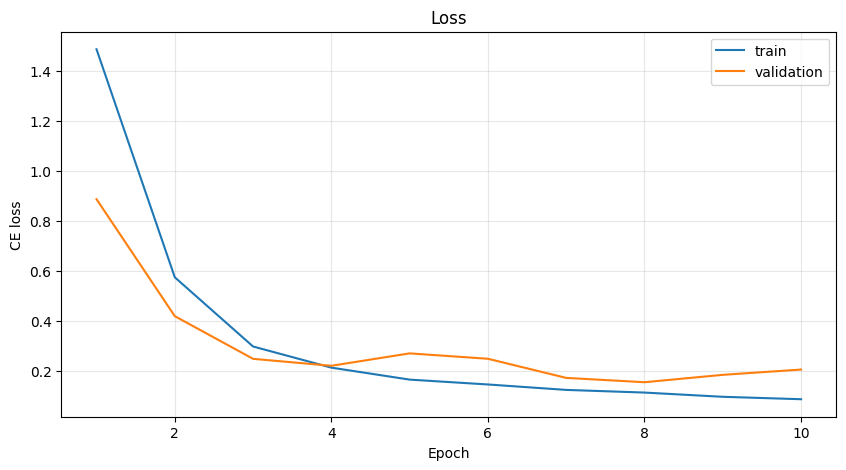

In [10]:
plot_loss(history)

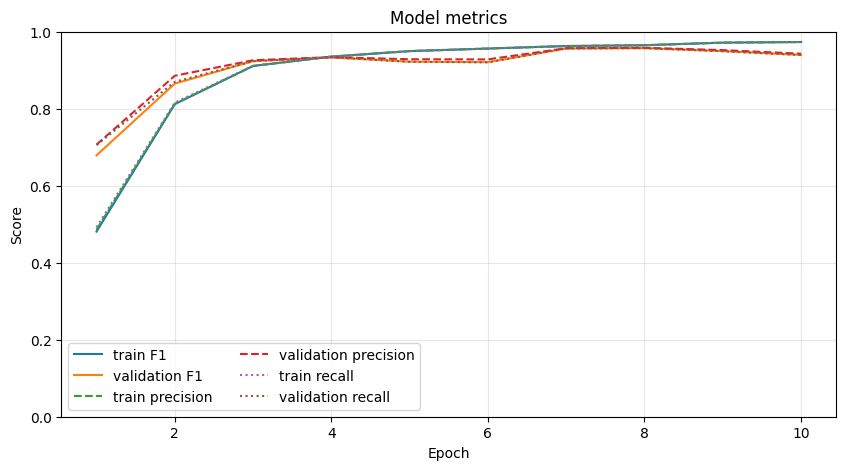

In [11]:
plot_metrics(history)

In [ ]:
checkpoint = torch.load("../mel.pt", map_location="cpu")

model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(DEVICE)

In [12]:
test_loss, test_metrics, test_true, test_pred = validate(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=DEVICE,
)

print(f"Test loss      : {test_loss:.4f}")

print(f"Test accuracy  : {test_metrics['accuracy']:.4f}")

print(f"Test precision : {test_metrics['precision']:.4f}")

print(f"Test recall    : {test_metrics['recall']:.4f}")

print(f"Test F1        : {test_metrics['f1']:.4f}")

Test loss      : 0.1632
Test accuracy  : 0.9504
Test precision : 0.9516
Test recall    : 0.9509
Test F1        : 0.9507


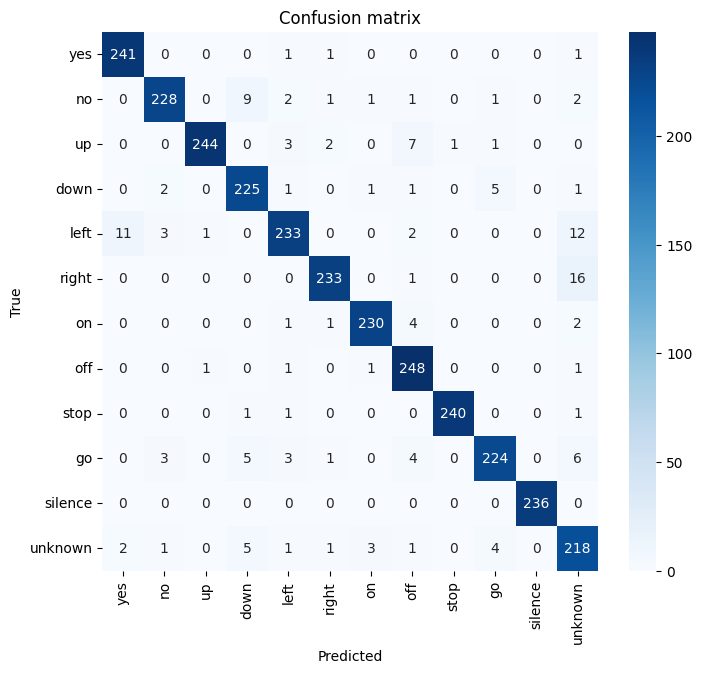

In [13]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(test_true, test_pred)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=ALL_CLASSES,
    yticklabels=ALL_CLASSES,
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")
plt.show()